# Electro-optic modulators: Pockels and Kerr cells, phase modulators and the Mach–Zehnder modulator

An electric field changes the indices of some crystals: linearly in
crystals without a centre of symmetry (the **Pockels** effect), and
quadratically in every medium (the **Kerr** effect). The changes are
tiny, $10^{-4}$ at most, but a phase change of $\pi$ needs only half a
wavelength of path difference, and the effect responds in femtoseconds.
Electro-optic modulators switch Q-switched lasers, pick pulses, stabilize
cavities and put the data on almost every long-haul optical link.

This notebook uses the `electrooptics` module with the crystal optics of
notebook 138 (crystal optics):

1. the Pockels effect in the index ellipsoid: KDP and LiNbO₃,
2. Pockels cells, longitudinal and transverse, the half-wave voltage and
   the field of view,
3. the Kerr cell,
4. phase modulation and its sidebands,
5. the Mach–Zehnder intensity modulator: transfer function, bias,
   extinction and chirp,
6. bandwidth: travelling-wave electrodes and velocity matching.

The modulator of notebook 120 (fibre link) is built from section 5.
Units: SI, with $r$ in pm/V in the tables.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import crystals as cr
from pyoptics import electrooptics as eo
from pyoptics import fibrecomm as fc
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. The Pockels effect in the index ellipsoid

The field changes the impermeability tensor $\eta = \varepsilon^{-1}$,
the matrix of the index ellipsoid, by
$\Delta\eta_i = \sum_k r_{ik}E_k$ (contracted indices
$i = xx, yy, zz, yz, xz, xy$). The symmetry of the crystal leaves only a
few $r_{ik}$. In **KDP** (point group $\bar 42m$) a field along the optic
axis $z$ adds an $xy$ term, $r_{63}E_z$: the ellipsoid, a circle in the
$x$–$y$ plane without field, becomes an ellipse with its axes at 45°,

$$n_{x',y'} = n_o \mp \tfrac12 n_o^3 r_{63}E_z.$$

In **LiNbO₃** (point group $3m$) a field along $z$ keeps the axes and
changes $n_e$ by $-\frac12 n_e^3 r_{33}E_z$ with the largest coefficient,
$r_{33} = 30.8$ pm/V. `eo.pockels_eps()` applies any $r$ matrix to any
tensor; `cr.wave_indices()` then gives the indices and the eigenwaves.

LiNbO3 r matrix (pm/V):
 [[ 0.  -3.4  8.6]
 [ 0.   3.4  8.6]
 [ 0.   0.  30.8]
 [ 0.  28.   0. ]
 [28.   0.   0. ]
 [-3.4  0.   0. ]]


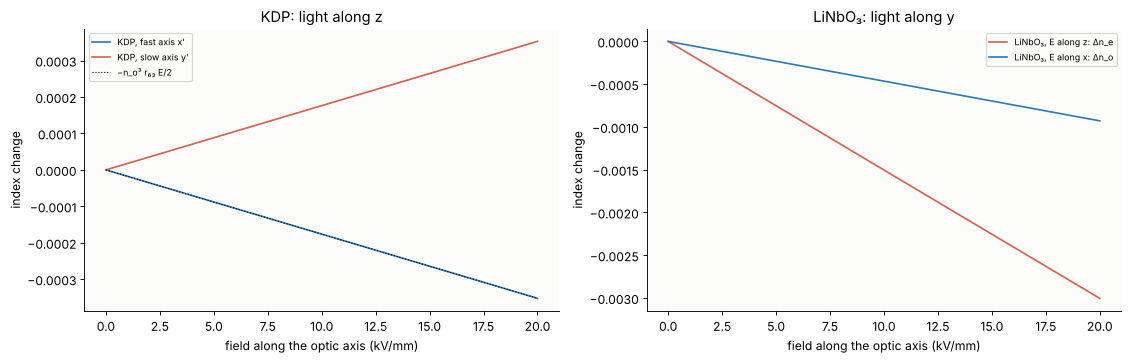

KDP eigen-axes at 45.0° from x for any field; LiNbO3 at 1 kV/mm: Δn_e = -1.50e-04, Δn_o = -4.65e-05


In [2]:
k = eo.KDP
eps_kdp = cr.uniaxial_eps(k["n_o"], k["n_e"])
r_kdp = eo.r_42m(k["r41"]*1e-12, k["r63"]*1e-12)
L_ = eo.LINBO3
eps_ln = cr.uniaxial_eps(L_["n_o"], L_["n_e"])
r_ln = eo.r_3m(L_["r13"]*1e-12, L_["r22"]*1e-12, L_["r33"]*1e-12, L_["r51"]*1e-12)
print("LiNbO3 r matrix (pm/V):\n", np.round(r_ln*1e12, 1))

E = np.linspace(0, 2e7, 41)                               # V/m, up to 20 kV/mm
nk, Dk, ln_n = [], [], []
for e in E:
    n, D, _, _ = cr.wave_indices(eo.pockels_eps(eps_kdp, r_kdp, (0, 0, e)), (0, 0, 1.0))
    nk.append(n.real)
    Dk.append(np.degrees(np.arctan2(D[0, 1].real, D[0, 0].real)) % 180)
    n2 = cr.wave_indices(eo.pockels_eps(eps_ln, r_ln, (0, 0, e)), (0, 1.0, 0))[0].real
    ln_n.append(n2)
nk, ln_n = np.array(nk), np.array(ln_n)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), layout="constrained")
ax[0].plot(E*1e-6, nk[:, 0] - k["n_o"], color=BLUE, label="KDP, fast axis x'")
ax[0].plot(E*1e-6, nk[:, 1] - k["n_o"], color=RED, label="KDP, slow axis y'")
ax[0].plot(E*1e-6, -0.5*k["n_o"]**3*k["r63"]*1e-12*E, "k:", lw=1, label="−n_o³ r₆₃ E/2")
ax[0].set_xlabel("field along the optic axis (kV/mm)"); ax[0].set_ylabel("index change")
ax[0].legend(fontsize=8); ax[0].set_title("KDP: light along z")
ax[1].plot(E*1e-6, ln_n[:, 0] - L_["n_e"], color=RED, label="LiNbO₃, E along z: Δn_e")
ax[1].plot(E*1e-6, ln_n[:, 1] - L_["n_o"], color=BLUE, label="LiNbO₃, E along x: Δn_o")
ax[1].set_xlabel("field along the optic axis (kV/mm)"); ax[1].set_ylabel("index change")
ax[1].legend(fontsize=8); ax[1].set_title("LiNbO₃: light along y")
plt.show()
print("KDP eigen-axes at {:.1f}° from x for any field; LiNbO3 at 1 kV/mm: Δn_e = {:.2e}, Δn_o = {:.2e}".format(
    Dk[-1], ln_n[2, 0] - L_["n_e"], ln_n[2, 1] - L_["n_o"]))

The full tensor calculation follows the first order formula. A field
of 1 kV/mm changes the index by only $1.8\times10^{-5}$ in KDP and
$1.5\times10^{-4}$ in LiNbO₃ (the plots go to 20 kV/mm, close to the
breakdown of air). In KDP the field turns the principal axes to 45° from
the crystal axes, whatever its strength; in LiNbO₃ $n_e$ changes 3.2
times more than $n_o$, so a field along $z$ both retards and phase shifts
light polarized along $z$.

## 2. Pockels cells

**Longitudinal.** In a KDP cell the field is applied along the beam,
through ring electrodes or transparent ones. The retardance between the
45° axes is $2\pi n_o^3r_{63}V/\lambda$ for the voltage $V$ across the
crystal, independent of its length, and between crossed polarizers at 0°
and 90° the cell transmits $\sin^2(\pi V/2V_\pi)$ with the **half-wave
voltage** $V_\pi = \lambda/(2n_o^3r_{63})$. Deuterated KDP (KD*P) has a
2.6 times larger $r_{63}$ and is the standard Q-switch for Nd:YAG lasers;
a quarter-wave voltage with a polarizer blocks the cavity, switching it
off opens it in nanoseconds.

**Transverse.** With the field across the beam the phase is
$\pi n^3 r \Gamma V L/(\lambda g)$: the voltage falls with the aspect ratio
$L/g$ of the crystal. In a titanium diffused LiNbO₃ waveguide the gap is
15 µm and a few centimetres of electrode bring $V_\pi$ to a few volts.

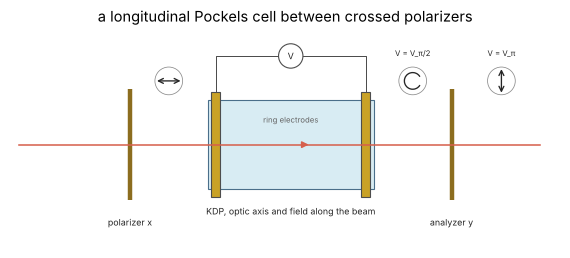

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
sketch.modulator_layout(ax, "pockels", title="a longitudinal Pockels cell between crossed polarizers")
plt.show()

KDP: V_pi = 15.1 kV at 1064 nm, 9.0 kV at 633 nm
KD*P: V_pi = 5.9 kV at 1064 nm, 3.5 kV at 633 nm


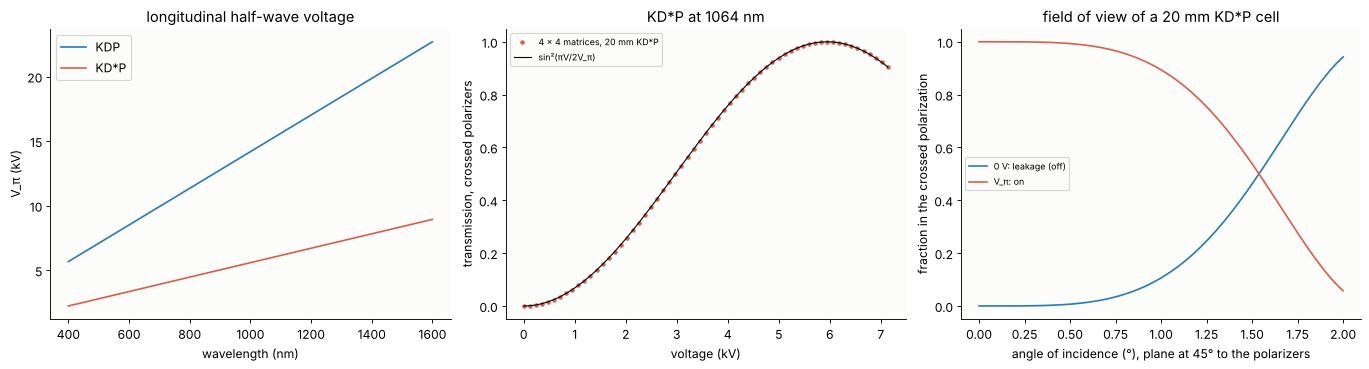

0 V leakage reaches 1 % at 0.55° incidence
transverse LiNbO3 waveguide, 15 µm gap, 40 mm electrode, overlap 0.6: V_pi = 3.22 V at 1550 nm


In [4]:
lam_v = np.linspace(400, 1600, 121)*1e-9
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), layout="constrained")
for name, d, c in (("KDP", eo.KDP, BLUE), ("KD*P", eo.KDP_DEUTERATED, RED)):
    ax[0].plot(lam_v*1e9, eo.half_wave_voltage(lam_v, d["n_o"], d["r63"]*1e-12)*1e-3, color=c, label=name)
    print("{}: V_pi = {:.1f} kV at 1064 nm, {:.1f} kV at 633 nm".format(
        name, *(eo.half_wave_voltage(np.array([1064e-9, 633e-9]), d["n_o"], d["r63"]*1e-12)*1e-3)))
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("V_π (kV)"); ax[0].legend()
ax[0].set_title("longitudinal half-wave voltage")
# transmission between crossed polarizers, by Jones matrices of the cell
lam0 = 1064e-9
d = eo.KDP_DEUTERATED
Vpi = eo.half_wave_voltage(lam0, d["n_o"], d["r63"]*1e-12)
V = np.linspace(0, 1.2*Vpi, 61)
T = []
eps_kdp_d = cr.uniaxial_eps(d["n_o"], d["n_e"])
r_d = eo.r_42m(d["r41"]*1e-12, d["r63"]*1e-12)
L_cell = 0.02
for v in V:
    t, _ = cr.stack_jones([(eo.pockels_eps(eps_kdp_d, r_d, (0, 0, v/L_cell)), L_cell)], lam0,
                          n_in=d["n_o"], n_out=d["n_o"], coherent=False)
    T.append(abs((t @ np.array([1.0, 0.0]))[1])**2)
ax[1].plot(V*1e-3, T, "o", ms=3, color=RED, label="4 × 4 matrices, 20 mm KD*P")
ax[1].plot(V*1e-3, np.sin(np.pi*V/(2*Vpi))**2, color="k", lw=1, label="sin²(πV/2V_π)")
ax[1].set_xlabel("voltage (kV)"); ax[1].set_ylabel("transmission, crossed polarizers"); ax[1].legend(fontsize=8)
ax[1].set_title("KD*P at 1064 nm")
# field of view of the longitudinal cell: KD*P is a C-plate
ang = np.linspace(0, 2, 201)
for v, c, lab in ((0.0, BLUE, "0 V: leakage (off)"), (Vpi, RED, "V_π: on")):
    eps_v = eo.pockels_eps(eps_kdp_d, r_d, (0, 0, v/L_cell))
    Tl = []
    for phi in (np.pi/4,):
        xi = np.sin(np.radians(ang))
        t, _ = cr.stack_jones([(eps_v, L_cell)], lam0, xi, n_in=1.0, n_out=1.0, coherent=False, azimuth=phi)
        Tl = np.abs(t[..., 1, 0])**2/(np.abs(t[..., 0, 0])**2 + np.abs(t[..., 1, 0])**2)
    ax[2].plot(ang, Tl, color=c, label=lab)
ax[2].set_xlabel("angle of incidence (°), plane at 45° to the polarizers")
ax[2].set_ylabel("fraction in the crossed polarization"); ax[2].legend(fontsize=8)
ax[2].set_title("field of view of a 20 mm KD*P cell")
plt.show()
xi1 = np.sin(np.radians(ang))
t0, _ = cr.stack_jones([(eps_kdp_d, L_cell)], lam0, xi1, coherent=False, azimuth=np.pi/4)
leak = np.abs(t0[..., 1, 0])**2/(np.abs(t0[..., 0, 0])**2 + np.abs(t0[..., 1, 0])**2)
print("0 V leakage reaches 1 % at {:.2f}° incidence".format(ang[np.argmax(leak > 0.01)]))
print("transverse LiNbO3 waveguide, 15 µm gap, 40 mm electrode, overlap 0.6: V_pi = {:.2f} V at 1550 nm".format(
    eo.transverse_half_wave_voltage(1.55e-6, L_["n_e"], L_["r33"]*1e-12, 0.04, 15e-6, 0.6)))

KD*P needs 5.9 kV at 1064 nm for a half wave and 3.0 kV for the quarter
wave of a Q-switch; KDP needs 2.6 times more. The 4 × 4 calculation with
the field-dependent tensor reproduces $\sin^2(\pi V/2V_\pi)$ exactly. A
longitudinal cell is a C-plate (notebook 138, crystal optics): off the axis its
natural birefringence $n_o - n_e$ leaks light between crossed polarizers
even at 0 V, 1 % at 0.55° in a 20 mm crystal. Pockels cells need
collimated beams, and Q-switches are placed where the beam is large and
parallel. The waveguide modulator needs 3.2 V instead of kilovolts: the
4 cm long, 15 µm narrow gap gains a factor of $L/g \approx 2700$.

## 3. The Kerr effect

Every medium becomes birefringent in a field, with the optic axis along
the field and $\Delta n = \lambda K E^2$ (Kerr constant $K$). Polar liquids
with aligned molecules have the largest $K$; nitrobenzene,
$K = 2.4\times10^{-12}$ m/V², was the classic shutter of high-speed
photography. The retardance $2\pi KLE^2$ is quadratic in the field.

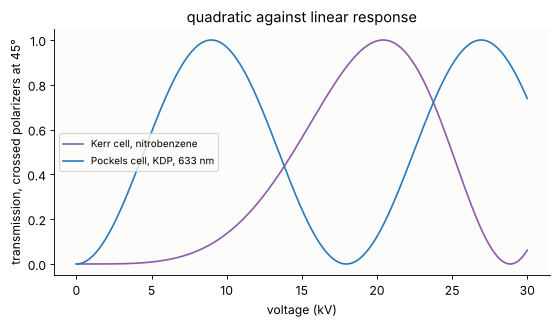

nitrobenzene, L = 5 cm, gap 1 cm: half wave at E = 2.04 kV/mm, V = 20.4 kV


In [5]:
Lk, g = 0.05, 0.01                                   # 5 cm electrodes, 1 cm apart
Ehalf = 1/np.sqrt(2*eo.NITROBENZENE_KERR*Lk)
Vk = np.linspace(0, 30e3, 301)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(Vk*1e-3, np.sin(eo.kerr_retardance(Vk/g, Lk)/2)**2, color=PURPLE, label="Kerr cell, nitrobenzene")
ax.plot(Vk*1e-3, np.sin(np.pi*Vk/(2*eo.half_wave_voltage(633e-9, eo.KDP["n_o"], eo.KDP["r63"]*1e-12)))**2,
        color=BLUE, label="Pockels cell, KDP, 633 nm")
ax.set_xlabel("voltage (kV)"); ax.set_ylabel("transmission, crossed polarizers at 45°"); ax.legend(fontsize=9)
ax.set_title("quadratic against linear response")
plt.show()
print("nitrobenzene, L = 5 cm, gap 1 cm: half wave at E = {:.2f} kV/mm, V = {:.1f} kV".format(Ehalf*1e-6, Ehalf*g*1e-3))

The 5 cm nitrobenzene cell needs 20 kV for a half wave, more than a KDP
Pockels cell at 633 nm (9 kV), and its slow start (quadratic) makes small
signals hard to modulate linearly. The Kerr effect of solids and glasses
is much weaker and is mostly met as an optical effect: the intensity of
light itself is the field (self-phase modulation, the topic of nonlinear
optics).

## 4. Phase modulation and sidebands

A single polarization along an eigenaxis only changes its phase. A sine
drive $V_0\sin\Omega t$ gives the field
$e^{i\beta\sin\Omega t} = \sum_n J_n(\beta)e^{in\Omega t}$: sidebands at
multiples of the drive frequency with powers $J_n(\beta)^2$, the
modulation index $\beta = \pi V_0/V_\pi$. At $\beta = 1.08$ the first
sidebands carry 22 % each (the Pound–Drever–Hall lock), at $\beta = 2.405$
the carrier vanishes; large $\beta$ make frequency combs of
$2\beta$ lines.

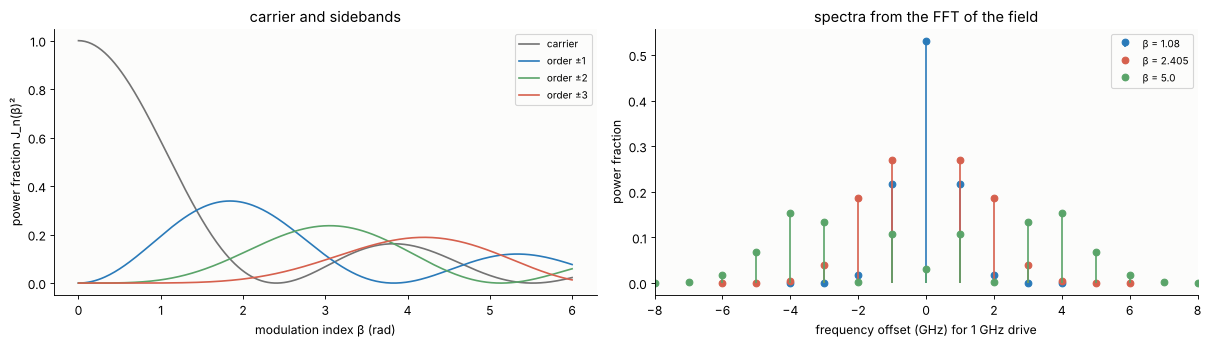

β = 1.08: carrier 0.53, first sidebands 0.22 each


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), layout="constrained")
bb = np.linspace(0, 6, 301)
for n_, c in zip(range(4), (GREY, BLUE, GREEN, RED)):
    ax[0].plot(bb, [eo.phase_modulation_sidebands(b, 6)[1][6 + n_] for b in bb], color=c, label=f"order ±{n_}" if n_ else "carrier")
ax[0].set_xlabel("modulation index β (rad)"); ax[0].set_ylabel("power fraction J_n(β)²"); ax[0].legend(fontsize=9)
ax[0].set_title("carrier and sidebands")
# the spectrum by FFT of a sampled phase modulated field
f_mod = 1.0                                           # GHz
t = np.arange(4096)/64.0                              # ns, 64 samples per ns
for b, c, off in ((1.08, BLUE, 0.0), (2.405, RED, 0.0), (5.0, GREEN, 0.0)):
    field = np.exp(1j*b*np.sin(2*np.pi*f_mod*t))
    S = np.abs(np.fft.fftshift(np.fft.fft(field)))**2/len(t)**2
    f = np.fft.fftshift(np.fft.fftfreq(len(t), t[1] - t[0]))
    sel = S > 1e-6
    ax[1].stem(f[sel] + off, S[sel], linefmt=c, markerfmt="o", basefmt=" ", label=f"β = {b}")
ax[1].set_xlim(-8, 8); ax[1].set_xlabel("frequency offset (GHz) for 1 GHz drive"); ax[1].set_ylabel("power fraction")
ax[1].legend(fontsize=9); ax[1].set_title("spectra from the FFT of the field")
plt.show()
n_, P = eo.phase_modulation_sidebands(1.08)
print("β = 1.08: carrier {:.2f}, first sidebands {:.2f} each".format(P[n_ == 0][0], P[n_ == 1][0]))

## 5. The Mach–Zehnder intensity modulator

Phase becomes amplitude in an interferometer. A LiNbO₃ Mach–Zehnder
modulator splits the light of a waveguide in a Y branch, sends the halves
through two arms between electrodes and recombines them:

$$E_\mathrm{out} = \tfrac12 E_\mathrm{in}\left(e^{i\varphi_1} + e^{i\varphi_2}\right),\qquad
P_\mathrm{out} = P_\mathrm{in}\cos^2\frac{\varphi_1 - \varphi_2}{2},$$

with $\varphi_k = \pi V_k/V_\pi$ plus a static bias. Three practical
points decide how good it is as a transmitter:

- **Bias.** For on–off keying it sits at quadrature, halfway between peak
  and null, and the drive swings $\pm V_\pi/2$ around it; a bias
  electrode holds it there against slow drifts of the crystal.
- **Extinction.** If the Y branches split $a : 1-a$ instead of 50:50, the
  null is not dark: the extinction ratio is $1/(2a-1)^2$, 26 dB for
  52.5:47.5 (`eo.mzm_extinction()`).
- **Chirp.** The output phase is $(\varphi_1 + \varphi_2)/2$. In
  **push-pull** (x-cut LiNbO₃, the arms see opposite fields) it is
  constant: pure amplitude modulation, $\alpha = 0$. A **single drive**
  (z-cut, one electrode over one arm) moves the phase with the amplitude:
  $\alpha = (V_1 + V_2)/(V_1 - V_2) = \pm1$, and the frequency follows
  $d\varphi/dt = (\alpha/2)\,d\ln P/dt$ as for a directly modulated laser,
  but with a sign that can be chosen by the bias slope.

`eo.mzm_nrz()` builds the field of an NRZ transmitter with a given
$V_\pi$, swing, splitting ratio and chirp, ready for `fibrecomm`.

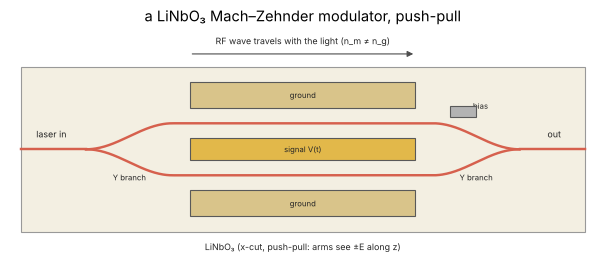

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.8))
sketch.modulator_layout(ax, "mzm", title="a LiNbO₃ Mach–Zehnder modulator, push-pull")
plt.show()

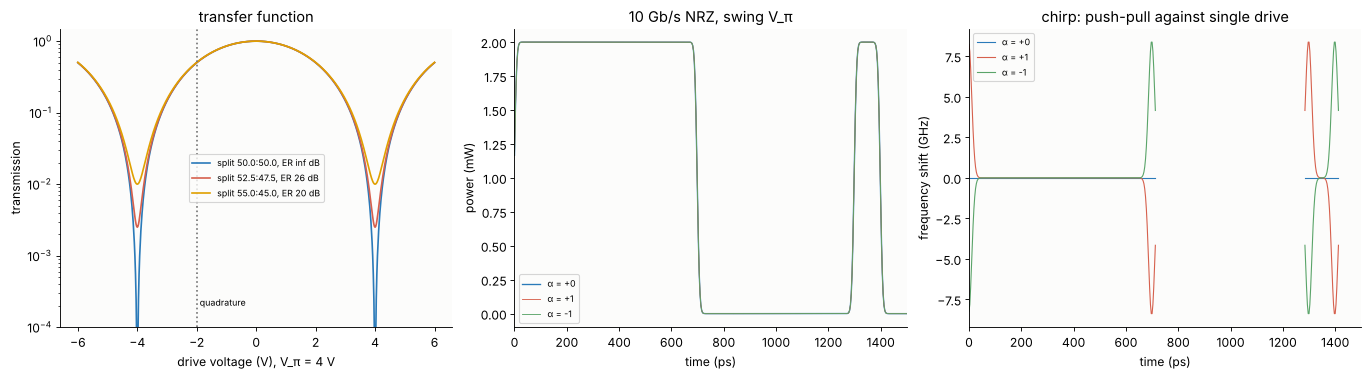

split 0.510: extinction ratio 34.0 dB
split 0.525: extinction ratio 26.0 dB
split 0.550: extinction ratio 20.0 dB
single drive: frequency shift at half power +8.4 / -8.4 GHz


In [8]:
Vpi_m = 4.0
Vd = np.linspace(-6, 6, 601)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
for a_, c in ((0.5, BLUE), (0.525, RED), (0.55, ORANGE)):
    P = eo.mzm_power(Vd, Vpi_m, bias=0.0, split=a_)
    ax[0].semilogy(Vd, P, color=c, label="split {:.1f}:{:.1f}, ER {:.0f} dB".format(
        100*a_, 100*(1 - a_), 10*np.log10(eo.mzm_extinction(a_)) if a_ != 0.5 else np.inf))
ax[0].set_ylim(1e-4, 1.5); ax[0].axvline(-Vpi_m/2, color=GREY, ls=":"); ax[0].text(-Vpi_m/2 + 0.1, 2e-4, "quadrature", fontsize=8)
ax[0].set_xlabel("drive voltage (V), V_π = 4 V"); ax[0].set_ylabel("transmission"); ax[0].legend(fontsize=8)
ax[0].set_title("transfer function")
bits = fc.prbs(7)
B = 10.0
for alpha, c in ((0.0, BLUE), (1.0, RED), (-1.0, GREEN)):
    t, A = eo.mzm_nrz(bits, B, V_pi=Vpi_m, alpha=alpha, p_in=2.0)
    nu = -np.gradient(np.unwrap(np.angle(A)), t)/(2*np.pi)*1e3
    nu[np.abs(A)**2 < 0.02*2.0] = np.nan                  # the phase is undefined in the zeros
    ax[1].plot(t, np.abs(A)**2, color=c, lw=1.2 if alpha == 0 else 0.8, label=f"α = {alpha:+.0f}")
    ax[2].plot(t, nu, color=c, lw=1.0, label=f"α = {alpha:+.0f}")
ax[1].set_xlim(0, 1500); ax[2].set_xlim(0, 1500)
ax[1].set_xlabel("time (ps)"); ax[1].set_ylabel("power (mW)"); ax[1].legend(fontsize=8)
ax[1].set_title("10 Gb/s NRZ, swing V_π")
ax[2].set_xlabel("time (ps)"); ax[2].set_ylabel("frequency shift (GHz)"); ax[2].legend(fontsize=8)
ax[2].set_title("chirp: push-pull against single drive")
plt.show()
for a_ in (0.51, 0.525, 0.55):
    print("split {:.3f}: extinction ratio {:.1f} dB".format(a_, 10*np.log10(eo.mzm_extinction(a_))))
t, A = eo.mzm_nrz(bits, B, V_pi=Vpi_m, alpha=1.0, p_in=2.0)
nu = -np.gradient(np.unwrap(np.angle(A)), t)/(2*np.pi)*1e3
half = np.abs(np.abs(A)**2 - 1.0) < 0.3            # near the half power points of the edges
print("single drive: frequency shift at half power {:+.1f} / {:+.1f} GHz".format(nu[half].max(), nu[half].min()))

With a swing of $V_\pi$ the transfer function compresses the edges of the
bits (the cosine flattens towards peak and null), so the eye is more
open than the drive. 1 % of imbalance in the splitter (51:49) still gives
34 dB of extinction, 5 % (55:45) only 20 dB. The single drive modulator
chirps by about ±8 GHz at the half power points of the edges (in the
zeros the phase is undefined and not plotted), less than the ±25 GHz of the
directly modulated laser in notebook 120 (fibre link), and in either
sense: with $\alpha < 0$ the rising edge is red shifted, which a fibre
with anomalous dispersion compresses at first (section 5 of
notebook 120, fibre link, shows the eye diagrams).

## 6. Bandwidth: travelling-wave electrodes

Above a few GHz the electrodes are a transmission line, and the drive
travels along the arm with the light. The light accumulates the phase
the voltage has at its own position and time; if the microwave index
$n_m$ differs from the optical group index $n_g$, the two drift apart,
and the response over the length $L$ is

$$H(f) = \frac{1 - e^{-\alpha L + iu}}{\alpha L - iu},\qquad u = 2\pi fL(n_m - n_g)/c,$$

with the microwave loss $\alpha \propto \sqrt f$ of the electrode (skin
effect). In LiNbO₃ $n_m \approx 4.2$ on a plain substrate (the static
dielectric constant is large) against $n_g = 2.18$, and the bandwidth–length
product is only about 6.6 GHz·cm. A thick buffer layer and a ridge
waveguide lower $n_m$ to the optical index; then the electrode loss
limits. Since $V_\pi$ falls as $1/L$ and the bandwidth as $1/L$ too,
modulators trade voltage against speed.

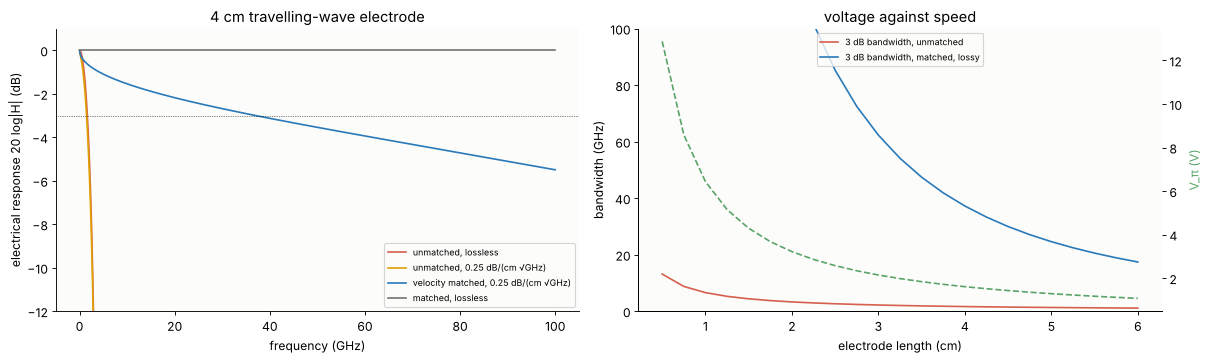

L = 1 cm: unmatched 6.6 GHz, matched with loss 349.4 GHz, push-pull V_pi 6.44 V
L = 4 cm: unmatched 1.6 GHz, matched with loss 37.2 GHz, push-pull V_pi 1.61 V


In [9]:
f = np.linspace(0, 100, 1001)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
for (nm, a0), c, lab in (((4.2, 0.0), RED, "unmatched, lossless"), ((4.2, 0.25), ORANGE, "unmatched, 0.25 dB/(cm √GHz)"),
                         ((2.2, 0.25), BLUE, "velocity matched, 0.25 dB/(cm √GHz)"), ((2.18, 0.0), GREY, "matched, lossless")):
    H = eo.travelling_wave_response(f, 0.04, n_m=nm, alpha0_db=a0)
    ax[0].plot(f, 20*np.log10(np.abs(H)), color=c, label=lab)
ax[0].set_ylim(-12, 1); ax[0].axhline(-3, color="k", lw=0.6, ls=":")
ax[0].set_xlabel("frequency (GHz)"); ax[0].set_ylabel("electrical response 20 log|H| (dB)"); ax[0].legend(fontsize=8)
ax[0].set_title("4 cm travelling-wave electrode")
Ls = np.linspace(0.5, 6, 23)*1e-2
f3_um = [eo.bandwidth_3db(L) for L in Ls]
f3_m = [eo.bandwidth_3db(L, n_m=2.2, alpha0_db=0.25) for L in Ls]
Vp = [eo.transverse_half_wave_voltage(1.55e-6, L_["n_e"], L_["r33"]*1e-12, L, 15e-6, 0.6)/2 for L in Ls]
ax[1].plot(Ls*100, f3_um, color=RED, label="3 dB bandwidth, unmatched")
ax[1].plot(Ls*100, f3_m, color=BLUE, label="3 dB bandwidth, matched, lossy")
ax[1].set_xlabel("electrode length (cm)"); ax[1].set_ylabel("bandwidth (GHz)"); ax[1].set_ylim(0, 100)
a2 = ax[1].twinx(); a2.plot(Ls*100, Vp, color=GREEN, ls="--", label="push-pull V_π"); a2.set_ylabel("V_π (V)", color=GREEN)
ax[1].legend(fontsize=8, loc="upper center"); ax[1].set_title("voltage against speed")
plt.show()
for L in (0.01, 0.04):
    print("L = {:.0f} cm: unmatched {:.1f} GHz, matched with loss {:.1f} GHz, push-pull V_pi {:.2f} V".format(
        L*100, eo.bandwidth_3db(L), eo.bandwidth_3db(L, n_m=2.2, alpha0_db=0.25),
        eo.transverse_half_wave_voltage(1.55e-6, L_["n_e"], L_["r33"]*1e-12, L, 15e-6, 0.6)/2))

A 4 cm electrode on a plain LiNbO₃ substrate reaches only 1.6 GHz; with
velocity matching and a loss of 0.25 dB/(cm √GHz) it reaches 37 GHz, now
limited by the electrode loss. Push-pull halves the voltage
(each arm takes half the phase), so 4 cm gives $V_\pi \approx 1.6$ V.
Commercial 40 Gb/s modulators are close to this: $V_\pi$ of 2 to 5 V and
30 to 40 GHz. Thin-film lithium niobate on insulator confines the light
to a micrometre and the field to a gap of a few micrometres, which brings
$V_\pi L$ down to about 2 V·cm with bandwidths above 100 GHz.

## Summary

- **Pockels effect:** $\Delta\eta = rE$ changes the index by
  $\frac12 n^3 rE$, $10^{-4}$ at kV/mm; in KDP the axes turn by 45°, in
  LiNbO₃ $n_e$ changes most ($r_{33} = 30.8$ pm/V).
- **Pockels cells:** longitudinal $V_\pi = \lambda/(2n_o^3r_{63})$, 5.9 kV
  for KD*P at 1064 nm, independent of the length, field of view of a
  fraction of a degree; transverse waveguides need volts.
- **Kerr cell:** quadratic, 20 kV for a nitrobenzene half wave.
- **Phase modulation:** sidebands $J_n(\beta)^2$.
- **Mach–Zehnder:** $\cos^2$ transfer, quadrature bias, extinction
  $1/(2a-1)^2$ from the splitter, chirp $\alpha = 0$ in push-pull and
  $\pm1$ with a single drive.
- **Bandwidth:** velocity mismatch limits a plain LiNbO₃ electrode to
  6.6 GHz·cm; matched electrodes reach tens of GHz, limited by loss,
  traded against $V_\pi \propto 1/L$.

In [10]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 3 s


## References

- A. Yariv and P. Yeh, *Photonics*, 6th ed., Oxford University Press
  (2007), chapter 9.
- B. E. A. Saleh and M. C. Teich, *Fundamentals of Photonics*, 3rd ed.,
  Wiley (2019), chapter 21.
- E. L. Wooten et al., "A review of lithium niobate modulators for
  fiber-optic communications systems", IEEE J. Sel. Top. Quantum
  Electron. 6, 69–82 (2000).
- F. Koyama and K. Iga, "Frequency chirping in external modulators",
  J. Lightwave Technol. 6, 87–93 (1988).
- C. Wang et al., "Integrated lithium niobate electro-optic modulators
  operating at CMOS-compatible voltages", Nature 562, 101–104 (2018).
- W. Koechner, *Solid-State Laser Engineering*, 6th ed., Springer
  (2006), chapter 8 (Q-switches).